# Vehicle Count Prediction (I-94 hourly traffic)

Predict how many vehicles a road sensor will count in an hour from the hour, weekday, weather and holidays. This is the piece that's actually useful for traffic planning: an estimate you can still produce when the camera or loop detector is offline.

Data: the UCI Metro Interstate Traffic Volume dataset (UCI id 492, CC BY 4.0). It has hourly westbound traffic volume on I-94 between Minneapolis and St Paul, recorded by MnDOT station 301, from October 2012 to September 2018, joined with hourly weather from OpenWeatherMap and US holidays. The file has 48,204 rows; after keeping one row per hour it is 40,575 hours.

An earlier version of this notebook also had a toy image-counting demo. I dropped it because I had no labeled real traffic images to test it on, and the tabular model is the part worth keeping.

In [1]:
import io, urllib.request, zipfile
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

OUT = Path('../../data/traffic'); OUT.mkdir(parents=True, exist_ok=True)

## Load the data

In [2]:
CSV = OUT / 'Metro_Interstate_Traffic_Volume.csv.gz'
if not CSV.exists():
    url = 'https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip'
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(OUT)
raw = pd.read_csv(CSV, parse_dates=['date_time'])
# the source has some duplicate hours (one row per weather description); keep the first
raw = raw.drop_duplicates(subset='date_time').sort_values('date_time').reset_index(drop=True)

# the holiday column is only filled on the midnight row of a holiday, so spread it to the whole day
day = raw['date_time'].dt.date
holiday_days = set(day[raw['holiday'].fillna('None') != 'None'])

df = pd.DataFrame({
    'date_time':  raw['date_time'],
    'hour':       raw['date_time'].dt.hour,
    'dow':        raw['date_time'].dt.dayofweek,
    'month':      raw['date_time'].dt.month,
    'is_holiday': day.isin(holiday_days).astype(int),
    'temp_c':     (raw['temp'] - 273.15).where(raw['temp'] > 0),   # a few rows have temp = 0 K
    'rain_1h':    raw['rain_1h'].clip(upper=50),                    # one row reports 9,831 mm
    'snow_1h':    raw['snow_1h'],
    'clouds':     raw['clouds_all'],
    'weather':    raw['weather_main'],
    'count':      raw['traffic_volume'],
})
df['temp_c'] = df['temp_c'].fillna(df['temp_c'].median())
print(df.shape, df['date_time'].min(), '->', df['date_time'].max())
df.head(4)

(40575, 11) 2012-10-02 09:00:00 -> 2018-09-30 23:00:00


,date_time,hour,dow,month,is_holiday,temp_c,rain_1h,snow_1h,clouds,weather,count
0,2012-10-02 09:00:00,9,1,10,0,15.13,0.0,0.0,40,Clouds,5545
1,2012-10-02 10:00:00,10,1,10,0,16.21,0.0,0.0,75,Clouds,4516
2,2012-10-02 11:00:00,11,1,10,0,16.43,0.0,0.0,90,Clouds,4767
3,2012-10-02 12:00:00,12,1,10,0,16.98,0.0,0.0,90,Clouds,5026


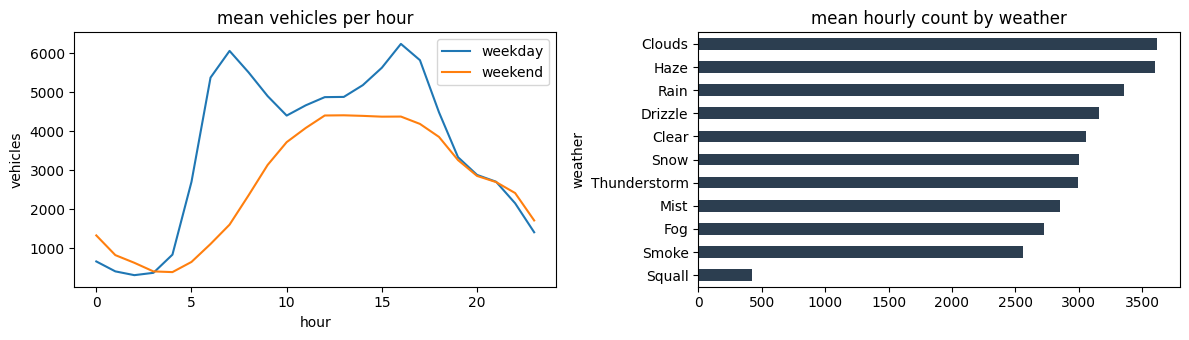

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
prof = df.assign(weekend=df['dow'] >= 5).groupby(['weekend', 'hour'])['count'].mean().unstack(0)
prof.columns = ['weekday', 'weekend']
prof.plot(ax=ax[0]); ax[0].set_title('mean vehicles per hour'); ax[0].set_ylabel('vehicles')
df.groupby('weather')['count'].mean().sort_values().plot.barh(ax=ax[1], color='#2c3e50')
ax[1].set_title('mean hourly count by weather')
plt.tight_layout(); plt.show()

## Regression with a time-based split

I train on everything before 2018 and test on 2018 (January to September), so the model is scored on hours it has never seen and that come after its training data. The baseline is the average count for the same hour and weekday in the training years.

In [4]:
X_all = pd.get_dummies(df.drop(columns=['date_time', 'count']), columns=['weather'], drop_first=True).astype(float)
y_all = df['count'].values
train = (df['date_time'] < '2018-01-01').values
X_tr, X_te, y_tr, y_te = X_all[train], X_all[~train], y_all[train], y_all[~train]
print('train hours:', len(X_tr), '| test hours:', len(X_te))

model = GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)

base = df[train].groupby(['dow', 'hour'])['count'].mean()
pred_base = base.reindex(pd.MultiIndex.from_arrays([df.loc[~train, 'dow'], df.loc[~train, 'hour']])).values

print(f'hour x weekday average  MAE = {mean_absolute_error(y_te, pred_base):6.1f}  R2 = {r2_score(y_te, pred_base):.3f}')
print(f'gradient boosting       MAE = {mean_absolute_error(y_te, pred):6.1f}  R2 = {r2_score(y_te, pred):.3f}')
print(f'mean hourly count in test: {y_te.mean():.0f}')

train hours: 34042 | test hours: 6533


hour x weekday average  MAE =  264.9  R2 = 0.944
gradient boosting       MAE =  241.2  R2 = 0.961
mean hourly count in test: 3324


In [5]:
imp = pd.Series(model.feature_importances_, index=X_all.columns).sort_values(ascending=False).head(8)
print(imp.round(3))

hour            0.866
dow             0.111
is_holiday      0.014
temp_c          0.005
month           0.003
rain_1h         0.001
clouds          0.000
weather_Snow    0.000
dtype: float64


## Caveats

- On the 6,533 test hours from 2018, gradient boosting gets MAE 241 vehicles per hour (R2 0.961), against MAE 265 (R2 0.944) for the plain hour-by-weekday average. The average hourly count is about 3,300, so both are useful, but the model only adds a little over the lookup table.
- That's because the calendar does almost all the work: hour of day alone has 0.87 of the feature importance and weekday another 0.11. Weather barely registers, which surprised me given Minnesota winters. Part of the reason is probably that the weather columns are coarse (one city-level reading per hour) and the big weather hits are rare.
- The errors that matter most in practice are the unusual hours (crashes, road work, events, storms), and nothing in these features can see them coming. A live system would use the last few hours of actual counts as features whenever the sensor is up, and fall back to this model only when it's down.
- There are gaps in the record (about 52,600 hours in the date range but only 40,575 in the file), and I haven't checked whether the 2018 test months behave differently from earlier years beyond the overall scores.